In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
# os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import time
tis1 =time.perf_counter()
import pandas as pd
import math
import numpy as np
import matplotlib.pyplot as plt
import random
#import tensorflow as tf#tensorflow1.x环境就用这个
import tensorflow.compat.v1 as tf#tensorflow2.x环境就用这两句
tf.get_logger().setLevel('ERROR')
tf.disable_v2_behavior()
from sklearn.preprocessing import MinMaxScaler
from scipy.io import savemat,loadmat
from matplotlib.pyplot import MultipleLocator
def fun(pop,P,T,Pt,Tt):
    tf.reset_default_graph()
    tf.set_random_seed(0)
    alpha = pop[0]# 学习率
    num_epochs = int(pop[1])#迭代次数
    hidden_nodes0 = int(pop[2])#第一隐含层神经元
    hidden_nodes = int(pop[3])#第二隐含层神经元
    input_features = P.shape[1]
    output_class =  T.shape[1] # 34输入 24输出
    batch_size = 200# batchsize
    # placeholder
    X = tf.placeholder("float", [None, input_features])
    Y = tf.placeholder("float", [None, output_class])
    
    # 定义一个隐层的神经网络
    def RNN(x,hidden_nodes0,hidden_nodes,input_features,output_class):
        x = tf.reshape(x , [-1, 1,input_features])
        # 定义输出层权重
        weights = {'out': tf.Variable(tf.random_normal([hidden_nodes, output_class]))}
        biases = {'out': tf.Variable(tf.random_normal([output_class]))}
        lstm_cell0 = tf.nn.rnn_cell.LSTMCell(hidden_nodes0)
        lstm_cell = tf.nn.rnn_cell.LSTMCell(hidden_nodes)
        lstm_cell = tf.nn.rnn_cell.MultiRNNCell([lstm_cell0,lstm_cell])
        #初始化
        init_state = lstm_cell.zero_state(tf.shape(x)[0], dtype=tf.float32)
        outputs, _ = tf.nn.dynamic_rnn(lstm_cell, x, dtype=tf.float32, initial_state=init_state)
        
        output_sequence = tf.matmul(tf.reshape(outputs, [-1, hidden_nodes]), weights['out']) + biases['out']
        return tf.reshape(output_sequence, [-1, output_class])
    
    logits = RNN(X,hidden_nodes0,hidden_nodes,input_features,output_class)
    loss = tf.losses.mean_squared_error(predictions = logits, labels = Y)
    global_step = tf.Variable(0)
    learning_rate = tf.train.exponential_decay(
                    alpha,
                    global_step,
                    num_epochs, 0.99,
                    staircase=True)
    optimizer = tf.train.AdamOptimizer(learning_rate=learning_rate, epsilon = 1e-10).minimize(loss,global_step=global_step)
    init = tf.global_variables_initializer()
    
    # 训练
    with tf.Session() as sess:
        sess.run(init)
        N = P.shape[0]
        for epoch in range(num_epochs):
            total_batch = int(math.ceil(N / batch_size))
            indices = np.arange(N)
            np.random.shuffle(indices)
            avg_loss = 0
            # 迭代训练，顺便计算训练集loss
            for i in range(total_batch):
                rand_index = indices[batch_size*i:batch_size*(i+1)]
                x = P[rand_index]
                y = T[rand_index]
                _, cost = sess.run([optimizer, loss],
                                    feed_dict={X: x, Y: y})
                avg_loss += cost / total_batch
        #计算测试集的预测值

        test_pred = sess.run(logits, feed_dict={X: Pt})
        test_pred = test_pred.reshape(-1, output_class)
    
    F2=np.mean(np.square((test_pred-Tt)))
    return F2

def boundary(pop,lb,ub):
    # 防止粒子跳出范围,除学习率之外 其他的都是整数
    pop=[int(pop[i]) if i>0 else pop[i] for i in range(len(lb))]
    for i in range(len(lb)):
        if pop[i]>ub[i] or pop[i]<lb[i]:
            if i==0:
                pop[i] = (ub[i]-lb[i])*np.random.rand()+lb[i]
            else:
                pop[i] = np.random.randint(lb[i],ub[i])
    return pop
def SSA(P,T,Pt,Tt):
    M=20
    pop=10
    P_percent=0.2
    dim=4 #搜索维度,第一个是学习率[0.001 0.01]
    #第二个是迭代次数[10-100] 
    #第三和第四个是隐含层节点数[1-100]
    Lb=[0.008,80, 40,  40]
    Ub=[0.015 ,120,60,60]
    #M 迭代次数
    #pop 麻雀种群数量
    #dim 寻优维度
    #P_percent 麻雀在生产者的比例
    pNum = round( pop *  P_percent )#pNum是生产者
    x=np.zeros((pop,dim))
    # print("len",len(x[0]))
    fit=np.zeros((pop,1))
    # 种群初始化
    for i in range(pop):    
        for j in range(dim):    
            if j==0:#学习率是小数 其他的是整数
                x[i][j] = (Ub[j]-Lb[j])*np.random.rand()+Lb[j]
            else:
                x[i][j] = np.random.randint(Lb[j],Ub[j])
        
        fit[ i ]  = fun( x[ i, : ],P,T,Pt,Tt )
    pFit = fit.copy()
    pX = x.copy()
    fMin=np.min( fit )
    bestI=np.argmin( fit )
    bestX = x[bestI, : ].copy()
    Convergence_curve=np.zeros((M,))
    result=np.zeros((M,dim))

    for t in range(M):
        sortIndex = np.argsort( pFit.reshape(-1,) ).reshape(-1,)
        fmax=np.max( pFit )
        B=np.argmax( pFit )
        worse= x[B,:].copy()
        r2=np.random.rand()
        ## 这一部分为发现者（探索者）的位置更新
        if r2<0.8:#%预警值较小，说明没有捕食者出现
            for i in range(pNum):#r2小于0.8时发现者改变位置
                r1=np.random.rand()
                x[sortIndex[i],:]=pX[sortIndex[i],:]*np.exp(-i/(r1*M))
                x[sortIndex[i],:]=boundary(x[sortIndex[i],:],Lb,Ub)
                temp=fun( x[ sortIndex[ i ], : ],P,T,Pt,Tt )
                fit[ sortIndex[ i ] ] = temp# 计算新的适应度值
        else:#预警值较大，说明有捕食者出现威胁到了种群的安全，需要去其它地方觅食
            for i in range(pNum):#r2大于0.8时发现者改变位置
                r1=np.random.rand()
                x[sortIndex[i],:]=pX[sortIndex[i],:] + np.random.normal()*np.ones((1,dim))
                x[sortIndex[i],:]=boundary(x[sortIndex[i],:],Lb,Ub)
                fit[ sortIndex[ i ] ] = fun( x[ sortIndex[ i ], : ],P,T,Pt,Tt )# 计算新的适应度值
        bestII=np.argmin( fit )
        bestXX = x[ bestII, : ].copy()
        
        ##这一部分为加入者（追随者）的位置更新
        for i in range(pNum + 1,pop):#剩下的个体变化
            A=np.floor(np.random.rand(1,dim)*2)*2-1
            if i > pop/2: #这个代表这部分麻雀处于十分饥饿的状态（因为它们的能量很低，也是是适应度值很差），需要到其它地方觅食
                x[ sortIndex[i ], : ]=np.random.normal()*np.exp((worse-pX[sortIndex[ i ], : ])/(i**2))
            else:#这一部分追随者是围绕最好的发现者周围进行觅食，其间也有可能发生食物的争夺，使其自己变成生产者
                
                x[ sortIndex[ i ], : ]=bestXX+np.abs( pX[ sortIndex[ i ], : ]-bestXX).dot(A.T*(A*A.T)**(-1))*np.ones((1,dim))
            x[sortIndex[ i ], : ] = boundary( x[ sortIndex[ i ], : ],Lb,Ub)#判断边界是否超出
            fit[ sortIndex[ i ] ] = fun( x[ sortIndex[ i ], : ],P,T,Pt,Tt )#计算适应度值        
        
        #这一部分为意识到危险（注意这里只是意识到了危险，不代表出现了真正的捕食者）的麻雀的位置更新
        c=random.sample(range(sortIndex.shape[0]),sortIndex.shape[0])#这个的作用是在种群中随机产生其位置（也就是这部分的麻雀位置一开始是随机的，意识到危险了要进行位置移动，
        b=sortIndex[np.array(c)[0:round(pop*0.2)]].reshape(-1,)
        for j in range(b.shape[0]):
            if pFit[sortIndex[b[j]]]> fMin:#处于种群外围的麻雀的位置改变
                x[ sortIndex[ b[j] ], : ]=bestX+np.random.normal(1,dim)*(np.abs( pX[ sortIndex[ b[j] ], : ]  -bestX))

            else: #处于种群中心的麻雀的位置改变
                x[ sortIndex[ b[j] ], : ] =pX[ sortIndex[ b[j] ], : ] + (2*np.random.rand()-1)*(np.abs(pX[ sortIndex[ b[j] ], : ]-worse)) / (pFit[sortIndex[b[j]]]-fmax+1e-50)
            x[ sortIndex[b[j] ], : ] = boundary( x[ sortIndex[b[j]], : ],Lb,Ub)
            fit[ sortIndex[b[j] ] ] = fun( x[ sortIndex[b[j] ], : ],P,T,Pt,Tt )#计算适应度值 
        
        # 这部分是最终的最优解更新
        for i in range(pop):
            if  fit[ i ] < pFit[ i ] :
                pFit[ i ] = fit[ i ].copy()
                pX[ i, : ] = x[ i, : ].copy()
        
            if  pFit[i ] < fMin:
                fMin= pFit[ i ,0].copy()
                bestX = pX[ i, :].copy()
        result[t,:]=bestX
        print(t+1,fMin,[int(bestX[i]) if i>0 else bestX[i] for i in range(len(Lb))])    

        Convergence_curve[t]=fMin
    return bestX,Convergence_curve,result

In [7]:
xlsfile=pd.read_excel(r'E:\预警的结果\国家电网数据集\数据\国家电网窃电检测.xlsx')# 前两列的日期不作为特征之一
print("SSA-LSTM参数优化开始：")
# print(xlsfile)
data=np.array(xlsfile)
# 拟用前一时期的 11 个特征与预测时期的前5个气象特征作为输入，预测时期的 6 种空气污染物浓度作为输出
in_=np.hstack((data[1:,:],data[0:-1,:]))
out_=data[1:,3:]
n=range(in_.shape[0])
m=6880 # 288个数据，选出220小时数据为训练集
train_data = in_[n[0:m],]
test_data = in_[n[m:],]
train_label = out_[n[0:m],]
test_label = out_[n[m:],]
# 归一化
ss_X=MinMaxScaler(feature_range=(0,1)).fit(train_data)
ss_y=MinMaxScaler(feature_range=(0,1)).fit(train_label)
train_data = ss_X.transform(train_data)
train_label = ss_y.transform(train_label)
test_data = ss_X.transform(test_data)
test_label = ss_y.transform(test_label)

SSA-LSTM参数优化开始：


In [8]:
best,trace,result=SSA(train_data,train_label,test_data,test_label)

1 3.7566122842012655e-08 [0.012113707181746088, 83, 49, 54]
2 3.7566122842012655e-08 [0.012113707181746088, 83, 49, 54]
3 3.7566122842012655e-08 [0.012113707181746088, 83, 49, 54]
4 3.7566122842012655e-08 [0.012113707181746088, 83, 49, 54]
5 3.7566122842012655e-08 [0.012113707181746088, 83, 49, 54]
6 3.7566122842012655e-08 [0.012113707181746088, 83, 49, 54]
7 3.7566122842012655e-08 [0.012113707181746088, 83, 49, 54]
8 2.7486468878088774e-08 [0.011556600109778603, 89, 56, 52]
9 2.7486468878088774e-08 [0.011556600109778603, 89, 56, 52]
10 2.7486468878088774e-08 [0.011556600109778603, 89, 56, 52]
11 2.7486468878088774e-08 [0.011556600109778603, 89, 56, 52]
12 2.7486468878088774e-08 [0.011556600109778603, 89, 56, 52]
13 2.7486468878088774e-08 [0.011556600109778603, 89, 56, 52]
14 2.7486468878088774e-08 [0.011556600109778603, 89, 56, 52]
15 2.7486468878088774e-08 [0.011556600109778603, 89, 56, 52]
16 2.7069392122176127e-08 [0.014752723733870772, 112, 57, 51]
17 2.7069392122176127e-08 [0.014

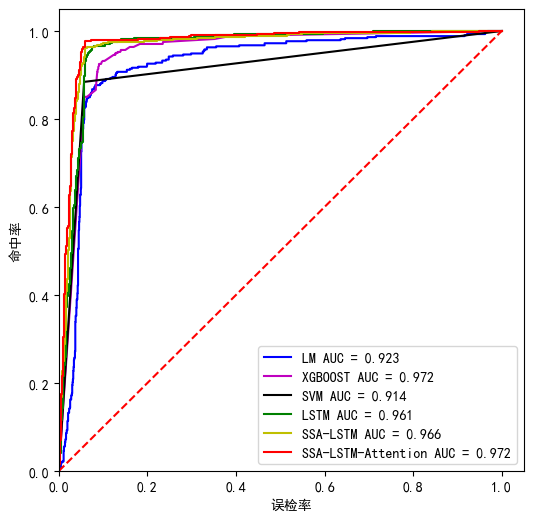

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
# -*- coding: utf-8 -*-
from pylab import *
mpl.rcParams['font.sans-serif'] = ['SimHei']
data1=pd.read_csv(r"E:\预警的结果\国家电网数据集\数据\结果\SSA-LSTM.CSV", encoding='ANSI')
data1=pd.DataFrame(data1)
data2=pd.read_csv(r"E:\预警的结果\国家电网数据集\数据\结果\SSA-LSTM-ATTENTION.CSV", encoding='ANSI')
data2=pd.DataFrame(data2)
data3=pd.read_csv(r"E:\预警的结果\国家电网数据集\数据\结果\LSTM.CSV", encoding='ANSI')
data3=pd.DataFrame(data3)
data4=pd.read_csv(r"E:\预警的结果\国家电网数据集\数据\结果\XGBOOST.CSV", encoding='ANSI')
data4=pd.DataFrame(data4)
data5=pd.read_csv(r"E:\预警的结果\国家电网数据集\数据\结果\svm.CSV", encoding='ANSI')
data5=pd.DataFrame(data5)
data6=pd.read_csv(r"E:\预警的结果\国家电网数据集\数据\结果\LM.CSV", encoding='ANSI')
data6=pd.DataFrame(data6)
from sklearn import metrics
fpr1, tpr1, threshold1 = metrics.roc_curve(list(data1['label']),list(data1['pred']))       # <class 'numpy.ndarray'> <class 'numpy.ndarray'>
roc_auc1 = metrics.auc(fpr1, tpr1)
fpr2, tpr2, threshold2 = metrics.roc_curve(list(data2['label']),list(data2['pred']))       # <class 'numpy.ndarray'> <class 'numpy.ndarray'>
roc_auc2 = metrics.auc(fpr2, tpr2)
fpr3, tpr3, threshold3 = metrics.roc_curve(list(data3['label']),list(data3['pred']))       # <class 'numpy.ndarray'> <class 'numpy.ndarray'>
roc_auc3 = metrics.auc(fpr3, tpr3)
fpr4, tpr4, threshold4 = metrics.roc_curve(list(data4['label']),list(data4['pred']))       # <class 'numpy.ndarray'> <class 'numpy.ndarray'>
roc_auc4 = metrics.auc(fpr4, tpr4)
fpr5, tpr5, threshold5= metrics.roc_curve(list(data5['label']),list(data5['pred']))       # <class 'numpy.ndarray'> <class 'numpy.ndarray'>
roc_auc5 = metrics.auc(fpr5, tpr5)
fpr6, tpr6, threshold6 = metrics.roc_curve(list(data6['label']),list(data6['pred']))       # <class 'numpy.ndarray'> <class 'numpy.ndarray'>
roc_auc6 = metrics.auc(fpr6, tpr6)
plt.figure(figsize=(6,6))
'''plt.title('Validation ROC')'''
plt.plot(fpr6, tpr6,'b',label = 'LM AUC = %0.3f' % roc_auc6)
plt.plot(fpr4, tpr4,'m',label = 'XGBOOST AUC = %0.3f' % roc_auc2)
plt.plot(fpr5, tpr5,'k',label = 'SVM AUC = %0.3f' % roc_auc5)
plt.plot(fpr3, tpr3,'g',label = 'LSTM AUC = %0.3f' % roc_auc3)
plt.plot(fpr1, tpr1,'y',label = 'SSA-LSTM AUC = %0.3f' % roc_auc1)
plt.plot(fpr2, tpr2,'r',label = 'SSA-LSTM-Attention AUC = %0.3f' % roc_auc2)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1.05])
plt.ylim([0, 1.05])
plt.ylabel('命中率')
plt.xlabel('误检率')
plt.savefig("filename.png")
plt.show()
plt.close()

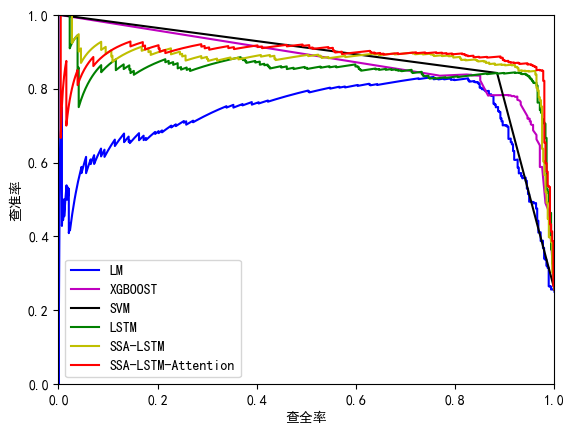

In [3]:
from sklearn.metrics import precision_recall_curve
precision1, recall1, thresholds1 = precision_recall_curve(list(data6['label']),list(data6['pred']))
plt.plot(recall1, precision1,'b',label = 'LM')
precision2, recall2, thresholds2 = precision_recall_curve(list(data4['label']),list(data4['pred']))
plt.plot(recall2, precision2,'m',label = 'XGBOOST')
precision3, recall3, thresholds3 = precision_recall_curve(list(data5['label']),list(data5['pred']))
plt.plot(recall3, precision3,'k',label = 'SVM')
precision4, recall4, thresholds4 = precision_recall_curve(list(data3['label']),list(data3['pred']))
plt.plot(recall4, precision4,'g',label = 'LSTM')
precision5, recall5, thresholds5 = precision_recall_curve(list(data1['label']),list(data1['pred']))
plt.plot(recall5, precision5,'y',label = 'SSA-LSTM')
precision6, recall6, thresholds6 = precision_recall_curve(list(data2['label']),list(data2['pred']))
plt.plot(recall6, precision6,'r',label = 'SSA-LSTM-Attention')
plt.xlim([0,1])
plt.ylim([0,1])
plt.legend(loc = 'lower left')
plt.ylabel('查准率')
plt.xlabel('查全率')
plt.show()
plt.close()

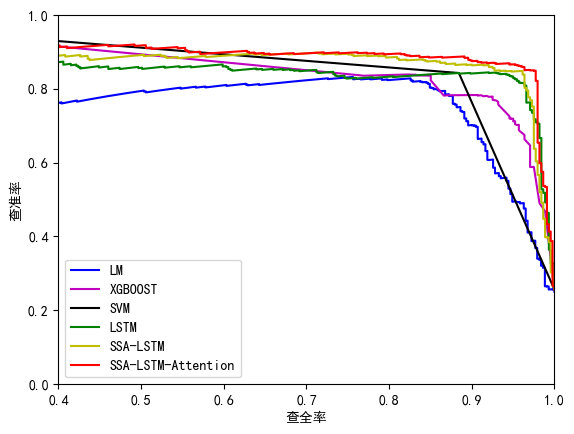

In [4]:
from sklearn.metrics import precision_recall_curve
precision1, recall1, thresholds1 = precision_recall_curve(list(data6['label']),list(data6['pred']))
plt.plot(recall1, precision1,'b',label = 'LM')
precision2, recall2, thresholds2 = precision_recall_curve(list(data4['label']),list(data4['pred']))
plt.plot(recall2, precision2,'m',label = 'XGBOOST')
precision3, recall3, thresholds3 = precision_recall_curve(list(data5['label']),list(data5['pred']))
plt.plot(recall3, precision3,'k',label = 'SVM')
precision4, recall4, thresholds4 = precision_recall_curve(list(data3['label']),list(data3['pred']))
plt.plot(recall4, precision4,'g',label = 'LSTM')
precision5, recall5, thresholds5 = precision_recall_curve(list(data1['label']),list(data1['pred']))
plt.plot(recall5, precision5,'y',label = 'SSA-LSTM')
precision6, recall6, thresholds6 = precision_recall_curve(list(data2['label']),list(data2['pred']))
plt.plot(recall6, precision6,'r',label = 'SSA-LSTM-Attention')
plt.xlim([0.4,1])
plt.ylim([0,1])
plt.legend(loc = 'lower left')
plt.ylabel('查准率')
plt.xlabel('查全率')
plt.show()
plt.close()

In [4]:
pip install seaborn

     ---------------------------------------- 0.0/293.3 kB ? eta -:--:--
     --- --------------------------------- 30.7/293.3 kB 640.0 kB/s eta 0:00:01
     ----- ------------------------------- 41.0/293.3 kB 326.8 kB/s eta 0:00:01
     ------------- ---------------------- 112.6/293.3 kB 652.2 kB/s eta 0:00:01
     --------------------- -------------- 174.1/293.3 kB 748.1 kB/s eta 0:00:01
     ----------------------------------- -- 276.5/293.3 kB 1.0 MB/s eta 0:00:01
     ------------------------------------ 293.3/293.3 kB 904.3 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


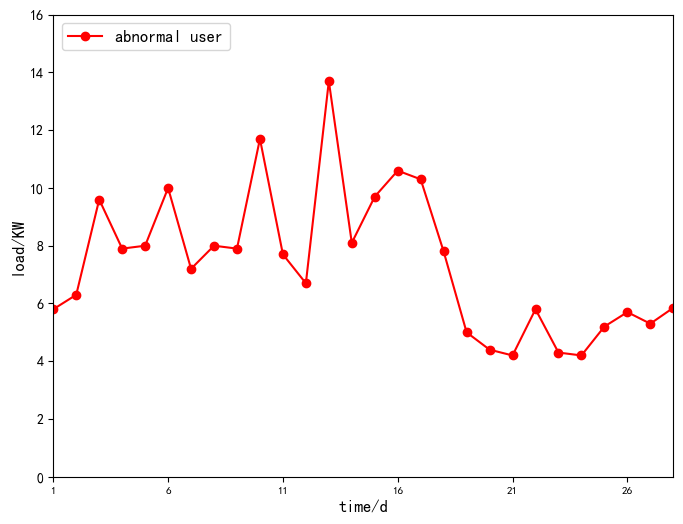

In [5]:
# -*- coding: utf-8 -*-
from pylab import *
mpl.rcParams['font.sans-serif'] = ['SimHei']
from cProfile import label
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
a=pd.read_excel('E:\预警的结果\国家电网数据集\数据\结果\peason.xlsx')
plt.figure(figsize=(8,6)) 
import matplotlib.pyplot as plt
plt.xlim(1,28)
plt.ylim(0,16)
'''b=list(a['zc'])'''
c=list(a['yc'])
'''plt.plot(b[1:49],'b') '''
plt.plot(c[0:30],'r-o')
plt.xticks(range(1,28,5),fontsize=8)
plt.yticks(fontsize=10)
plt.title('',fontsize=20)
plt.xlabel('time/d',fontsize=12)
plt.ylabel("load/KW",fontsize=12)
#控制图的显示， 把图例显示在做下角
plt.legend(["abnormal user"],  loc='upper left',fontsize=12)
plt.show()

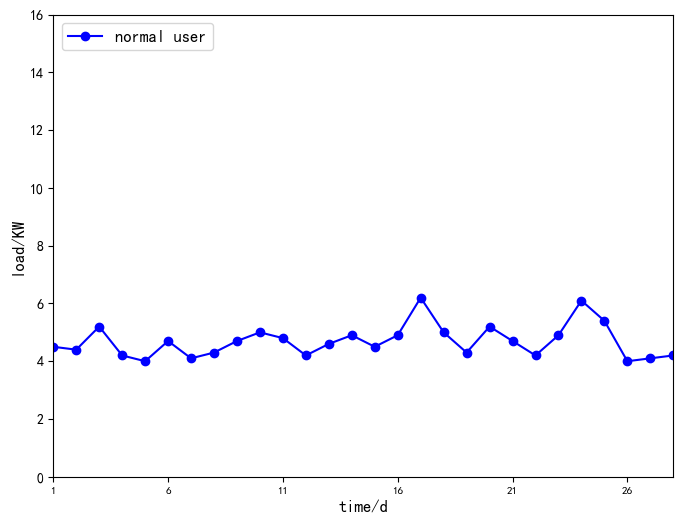

In [6]:
# -*- coding: utf-8 -*-
from pylab import *
mpl.rcParams['font.sans-serif'] = ['SimHei']
from cProfile import label
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
a=pd.read_excel('E:\预警的结果\国家电网数据集\数据\结果\peason.xlsx')
plt.figure(figsize=(8,6)) 
import matplotlib.pyplot as plt
plt.xlim(1,28)
plt.ylim(0,16)
'''b=list(a['zc'])'''
c=list(a['zc'])
'''plt.plot(b[1:49],'b') '''
plt.plot(c[0:30],'b-o')
plt.xticks(range(1,28,5),fontsize=8)
plt.yticks(fontsize=10)
plt.title('',fontsize=20)
plt.xlabel('time/d',fontsize=12)
plt.ylabel("load/KW",fontsize=12)
#控制图的显示， 把图例显示在做下角
plt.legend(["normal user"],  loc='upper left',fontsize=12)
plt.show()

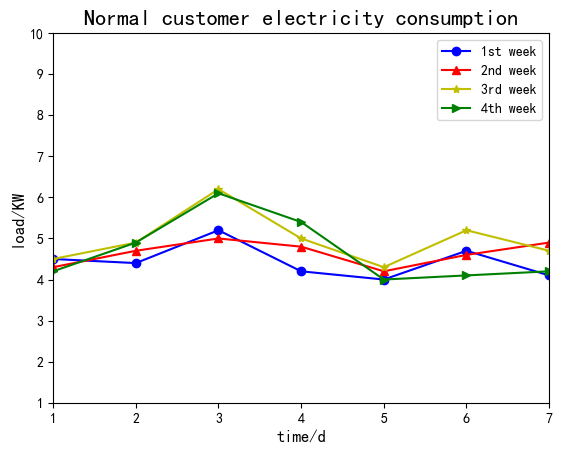

In [13]:
d=pd.read_excel('E:\预警的结果\国家电网数据集\数据\结果\peason\peason1.xlsx')
plt.xlim(1,7)
plt.ylim(1,10)
p=list(d['zc1'])
q=list(d['zc2'])
r=list(d['zc3'])
s=list(d['zc4'])
plt.plot(p[0:8],'b-o')
plt.plot(q[0:8],'r-^')
plt.plot(r[0:8],'y-*') 
plt.plot(s[0:8],'g->') 
plt.xticks(range(1,8,1),fontsize=10)
plt.yticks(fontsize=10)
plt.title('Normal customer electricity consumption',fontsize=16)
plt.xlabel('time/d',fontsize=12)
plt.ylabel("load/KW",fontsize=12)
#控制图的显示， 把图例显示在做下角
plt.legend(["1st week","2nd week","3rd week","4th week"],  loc='upper right',fontsize=10)
plt.show()

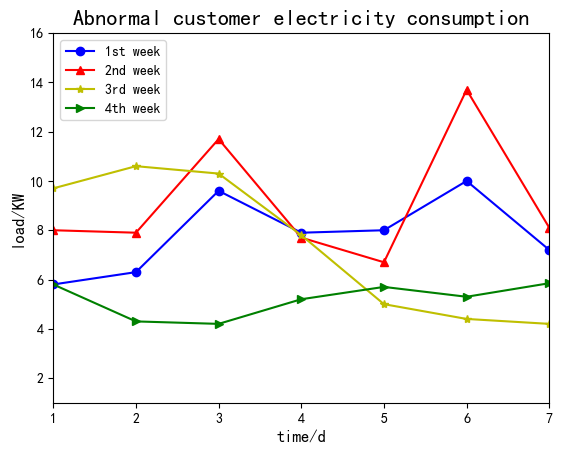

In [12]:
a=pd.read_excel('E:\预警的结果\国家电网数据集\数据\结果\peason\peason2.xlsx')
plt.xlim(1,7)
plt.ylim(1,16)
l=list(a['yc1'])
m=list(a['yc2'])
n=list(a['yc3'])
o=list(a['yc4'])
plt.plot(l[0:8],'b-o')
plt.plot(m[0:8],'r-^')
plt.plot(n[0:8],'y-*') 
plt.plot(o[0:8],'g->') 
plt.xticks(range(1,8,1),fontsize=10)
plt.yticks(fontsize=10)
plt.title('Abnormal customer electricity consumption',fontsize=16)
plt.xlabel('time/d',fontsize=12)
plt.ylabel("load/KW",fontsize=12)
#控制图的显示， 把图例显示在做下角
plt.legend(["1st week","2nd week","3rd week","4th week"],  loc='upper left',fontsize=10)
plt.show()

   1st week  2nd week  3rd week  4th week
0       5.8       8.0       9.7      5.80
1       6.3       7.9      10.6      4.30
2       9.6      11.7      10.3      4.20
3       7.9       7.7       7.8      5.20
4       8.0       6.7       5.0      5.70
5      10.0      13.7       4.4      5.30
6       7.2       8.1       4.2      5.85
皮尔逊系数
          1st week  2nd week  3rd week  4th week
1st week  1.000000  0.780426 -0.345995 -0.265105
2nd week  0.780426  1.000000 -0.096380 -0.337181
3rd week -0.345995 -0.096380  1.000000 -0.674255
4th week -0.265105 -0.337181 -0.674255  1.000000


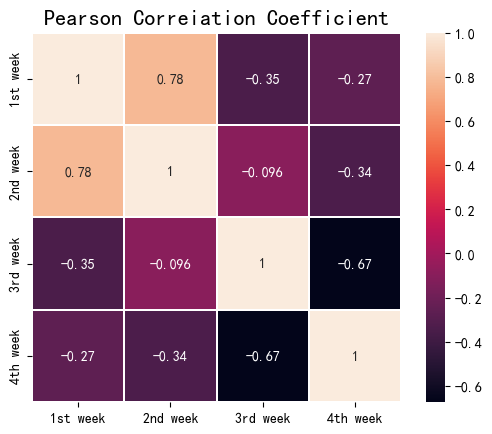

In [20]:
 #coding=utf-8
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
a=pd.read_excel('E:\预警的结果\国家电网数据集\数据\结果\peason\peason2.xlsx')
df = pd.DataFrame(a)
print(a)
a=df.corr()
print('皮尔逊系数')
print(a)
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
sns.heatmap(df.corr(method='pearson'),linewidths=0.1,vmax=1.0, square=True,linecolor='white', annot=True)
plt.title('Pearson Correiation Coefficient',fontsize=16)
plt.show()

   1st week  2nd week  3rd week  4th week
0       4.5       4.3       4.5       4.2
1       4.4       4.7       4.9       4.9
2       5.2       5.0       6.2       6.1
3       4.2       4.8       5.0       5.4
4       4.0       4.2       4.3       4.0
5       4.7       4.6       5.2       4.1
6       4.1       4.9       4.7       4.2
皮尔逊系数
          1st week  2nd week  3rd week  4th week
1st week  1.000000  0.415532  0.878971  0.597070
2nd week  0.415532  1.000000  0.734181  0.696289
3rd week  0.878971  0.734181  1.000000  0.815140
4th week  0.597070  0.696289  0.815140  1.000000


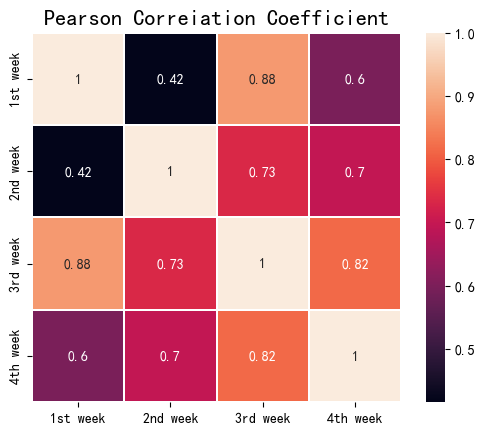

In [21]:
 #coding=utf-8
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
a=pd.read_excel('E:\预警的结果\国家电网数据集\数据\结果\peason\peason1.xlsx')
df = pd.DataFrame(a)
print(a)
a=df.corr()
print('皮尔逊系数')
print(a)
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
sns.heatmap(df.corr(method='pearson'),linewidths=0.1,vmax=1.0, square=True,linecolor='white', annot=True)
plt.title('Pearson Correiation Coefficient',fontsize=16)
plt.show()

In [1]:
 #coding=utf-8
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
a=pd.read_excel(r'D:\大论文\窃电数据.xlsx')
df = a.iloc[:,0]
da =a.iloc[:,1]
db=a.iloc[:,2]
dc=a.iloc[:,3]
dd=a.iloc[:,4]
de=a.iloc[:,5]
dg=a.iloc[:,6]
dh=a.iloc[:,7]
di=a.iloc[:,8]
dj=a.iloc[:,9]

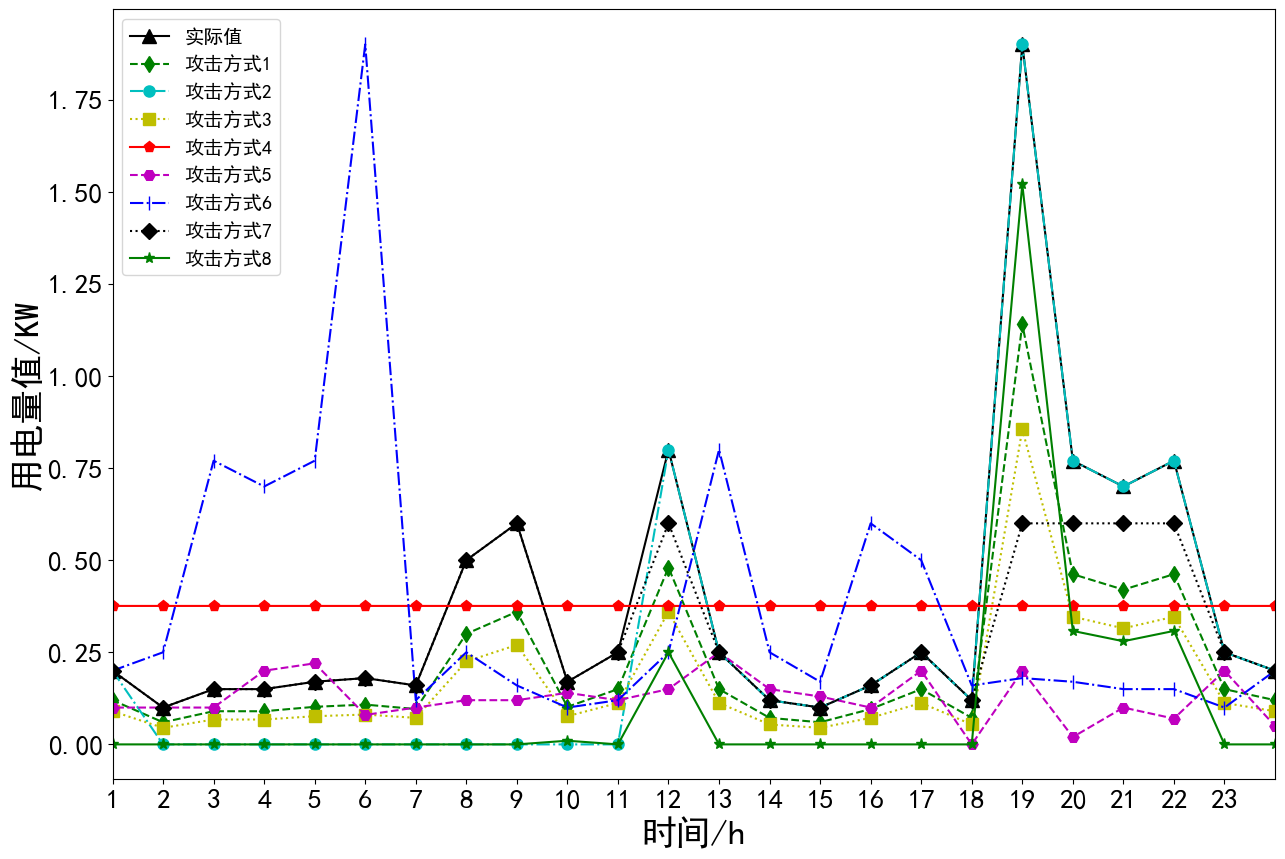

In [6]:
# -*- coding: utf-8 -*-
from pylab import *
mpl.rcParams['font.sans-serif'] = ['SimHei']
 #coding=utf-8
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.figure(figsize=(15,10)) 
import matplotlib.pyplot as plt
plt.xlim(1,24)
# 修改代码开始
plt.plot(da[:25],'k', linestyle='-', marker='^', markersize=10)
plt.plot(db[:25],'g', linestyle='--', marker='d', markersize=8) 
plt.plot(dc[:25],'c', linestyle='-.', marker='o', markersize=8)
plt.plot(dd[:25],'y', linestyle=':', marker='s', markersize=8) 
plt.plot(de[:25],'r', linestyle='-', marker='p', markersize=8)
plt.plot(dg[:25],'m', linestyle='--', marker='H', markersize=8) 
plt.plot(dh[:25],'b', linestyle='-.', marker='|', markersize=10)
plt.plot(di[:25],'k', linestyle=':', marker='D', markersize=8)
plt.plot(dj[:25],'g', linestyle='-', marker='*', markersize=8)
'''plt.plot(da[:24],'k')
plt.plot(db[:24],'g') 
plt.plot(dc[:24],'c')
plt.plot(dd[:24],'y') 
plt.plot(de[:24], )
plt.plot(dg[:24],'m') 
plt.plot(dh[:24],)
plt.plot(di[:24],)
plt.plot(dj[:24],)'''
plt.xticks(range(1,24,1),fontsize=20)
plt.yticks(fontsize=20)
'''plt.title('负荷预测',fontsize=40)'''
plt.xlabel('时间/h',fontsize=25)
plt.ylabel("用电量值/KW",fontsize=25)
#控制图的显示， 把图例显示在做下角
plt.legend(["实际值", "攻击方式1","攻击方式2","攻击方式3","攻击方式4","攻击方式5","攻击方式6","攻击方式7","攻击方式8","攻击方式9"], loc='upper left',fontsize=14)
plt.show()

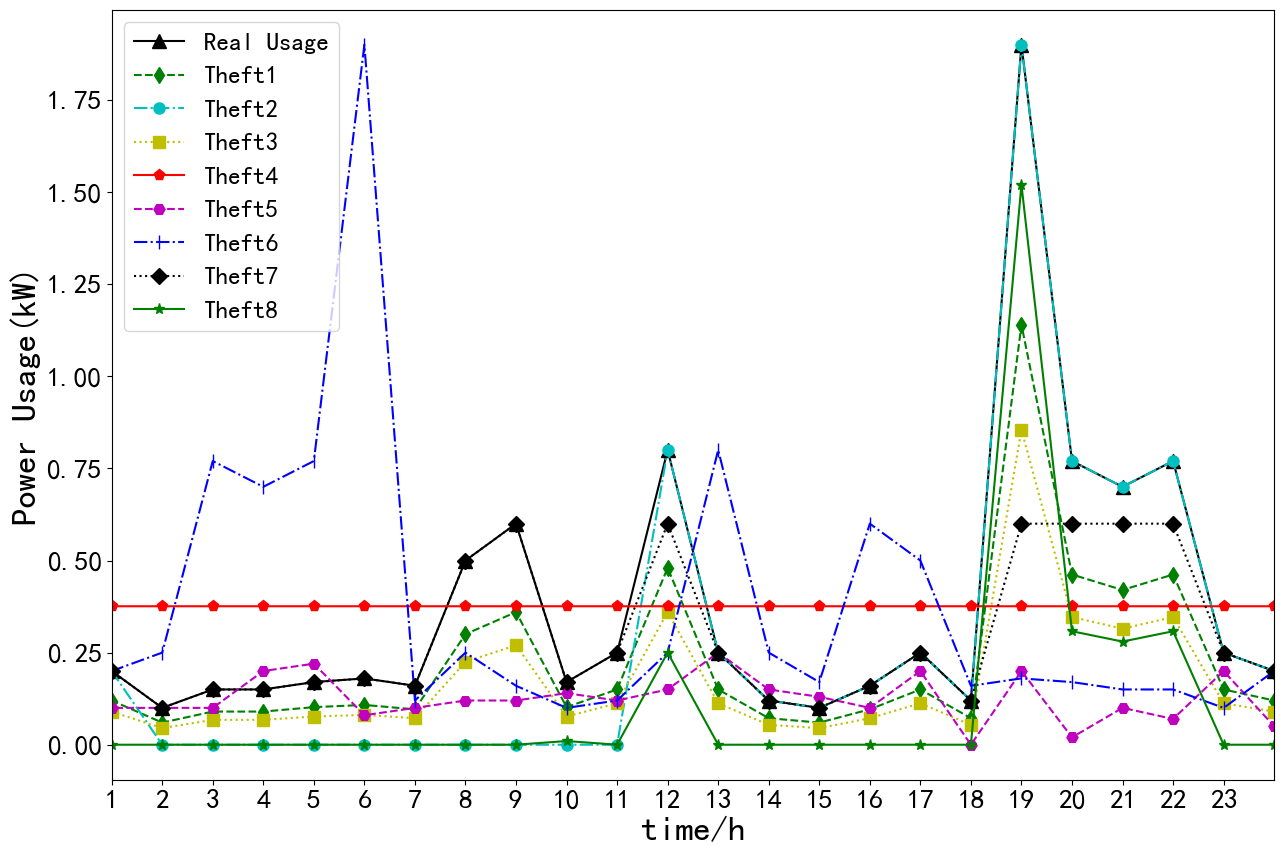

In [7]:
# -*- coding: utf-8 -*-
from pylab import *
mpl.rcParams['font.sans-serif'] = ['SimHei']
 #coding=utf-8
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.figure(figsize=(15,10)) 
import matplotlib.pyplot as plt
plt.xlim(1,24)
# 修改代码开始
plt.plot(da[:25],'k', linestyle='-', marker='^', markersize=10)
plt.plot(db[:25],'g', linestyle='--', marker='d', markersize=8) 
plt.plot(dc[:25],'c', linestyle='-.', marker='o', markersize=8)
plt.plot(dd[:25],'y', linestyle=':', marker='s', markersize=8) 
plt.plot(de[:25],'r', linestyle='-', marker='p', markersize=8)
plt.plot(dg[:25],'m', linestyle='--', marker='H', markersize=8) 
plt.plot(dh[:25],'b', linestyle='-.', marker='|', markersize=10)
plt.plot(di[:25],'k', linestyle=':', marker='D', markersize=8)
plt.plot(dj[:25],'g', linestyle='-', marker='*', markersize=8)
'''plt.plot(da[:24],'k')
plt.plot(db[:24],'g') 
plt.plot(dc[:24],'c')
plt.plot(dd[:24],'y') 
plt.plot(de[:24], )
plt.plot(dg[:24],'m') 
plt.plot(dh[:24],)
plt.plot(di[:24],)
plt.plot(dj[:24],)'''
plt.xticks(range(1,24,1),fontsize=20)
plt.yticks(fontsize=20)
'''plt.title('负荷预测',fontsize=40)'''
plt.xlabel('time/h',fontsize=25)
plt.ylabel("Power Usage(kW)",fontsize=25)
#控制图的显示， 把图例显示在做下角
plt.legend(["Real Usage", "Theft1","Theft2","Theft3","Theft4","Theft5","Theft6","Theft7","Theft8","Theft9"], loc='upper left',fontsize=18)
plt.show()